In [1]:
import numpy as np
from matplotlib import pyplot as plt
import enlighten
import shapely

from scipy.interpolate import interp1d

from utils import Modulator_CPW


from imodulator.ChargeSimulator import ChargeSimulatorSolcore
from imodulator.OpticalSimulator import OpticalSimulatorFEMWELL, OpticalSimulatorMODE
from imodulator.ElectroOpticalSimulator import ElectroOpticalSimulator
from imodulator.RFSimulator import RFSimulatorFEMWELL as RFSimulator

import skrf as rf

import os
import json

%matplotlib widget

Failed to import lumapi: [Errno 2] No such file or directory: 'C:/Program Files/Lumerical/v232/api/python/lumapi.py'


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\solcore\registries.py:73: UserWarning: Optics solver 'RCWA' will not be available. An installation of S4 has not been found.
  warn(
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\nextnanopy\defaults.py:202: UserWarning: Unsupported products in config file: ['nextnano.NEGF++'] will be ignored. To not see this message, please remove unsupported products from the config file: C:\Users\20230622\.nextnanopy-configNote: nextnano.NEGF++ was renamed to nextnano.NEGF, nextnano.NEGF was renamed to nextnano.NEGF_classic. Please check the documentation for more details.
  warnings.warn(


Successfully imported nextnanopy
Successfully configured nextnano++ settings
  [OK] nextnano++ exe: C:/Program Files/nextnano/2026_07_03/nextnano++/bin/nextnano++_Intel_64bit.exe
  [OK] nextnano++ license: C:/Users/20230622/OneDrive - TU Eindhoven/PhD/License_nnp.lic
  [OK] nextnano++ database: C:/Program Files/nextnano/2026_07_03/nextnano++/database/database.nnp
  [OK] nextnano++ outputdirectory: D:/Repos/imodulator/tests\nn_output
nextnano configuration test passed: all paths are valid.


(<Figure size 640x480 with 1 Axes>, <Axes: >)

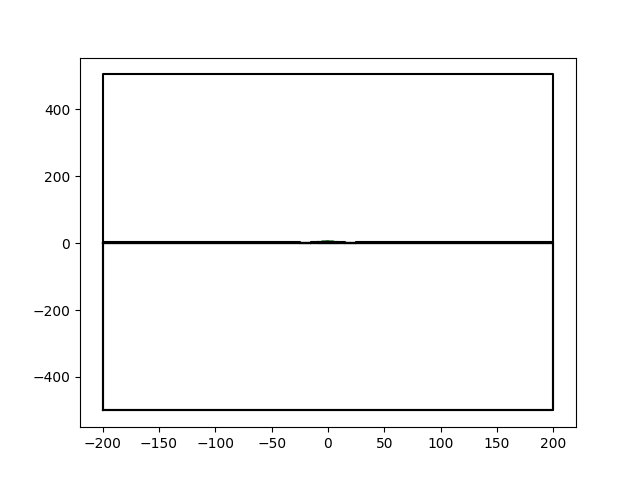

: 

In [ ]:
modulator = Modulator_CPW()
modulator.device.plot_polygons()

15440


(<Figure size 800x400 with 4 Axes>,
 [<Axes: title={'center': '$\\epsilon_{xx}$ real part'}, xlabel='x (um)', ylabel='y (um)'>,
  <Axes: title={'center': '$\\epsilon_{xx}$ imaginary part'}, xlabel='x (um)', ylabel='y (um)'>])

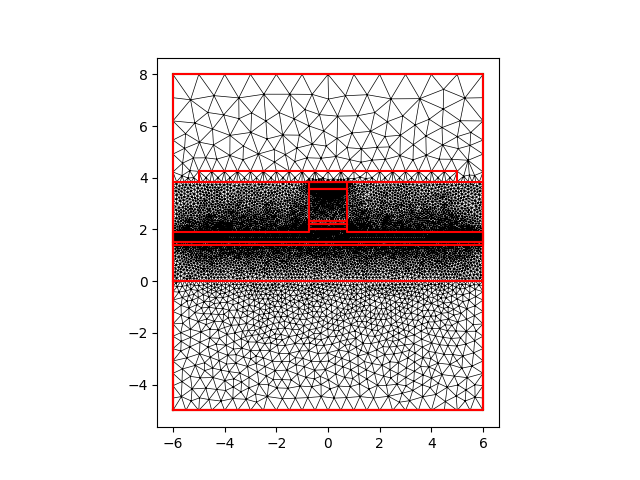

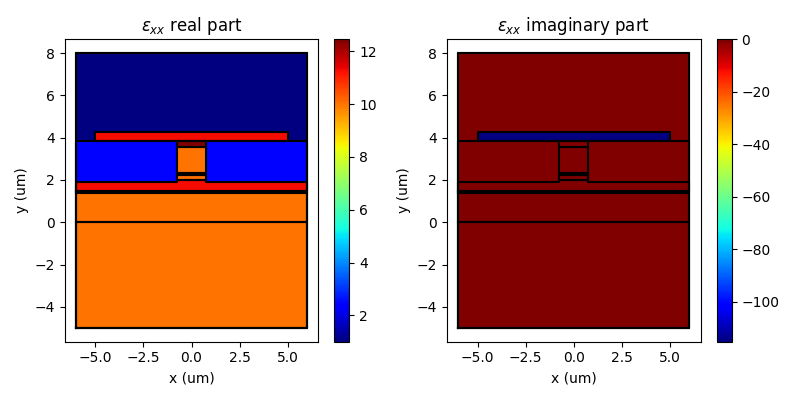

In [3]:
mode = OpticalSimulatorFEMWELL(
            device=modulator.device,
			simulation_window=shapely.box(-6, -5, 6,8),
            include_metals=True
        )
mode.make_mesh(gmsh_algorithm=1)
mode.plot_mesh()

print(mode.mesh.nelements)

mode.plot_epsilon_optical()

Group index: 3.6697
Effective index - mode 0: 3.2400
loss - mode 0: 2.54 dB/cm
power:  (1+0j)
TE fraction:  0.9981896460729606
TM fraction:  0.001810353927039432
transversality: 0.9896735649586915
#------------------------------------------#
Effective index - mode 1: 3.2342
loss - mode 1: 3.37 dB/cm
power:  (0.9999999999999998+0j)
TE fraction:  0.0025862802807467273
TM fraction:  0.9974137197192533
transversality: 0.9712208772579947
#------------------------------------------#
Effective index - mode 2: 3.1986
loss - mode 2: 2.09 dB/cm
power:  (1.0000000000000002+0j)
TE fraction:  0.9990585025643559
TM fraction:  0.0009414974356440897
transversality: 0.9982407185612395
#------------------------------------------#
Effective index - mode 3: 3.1979
loss - mode 3: 2.12 dB/cm
power:  (0.9999999999999999+0j)
TE fraction:  0.9994269964143013
TM fraction:  0.0005730035856986726
transversality: 0.9994485454123039
#------------------------------------------#
Effective index - mode 4: 3.1954
loss 

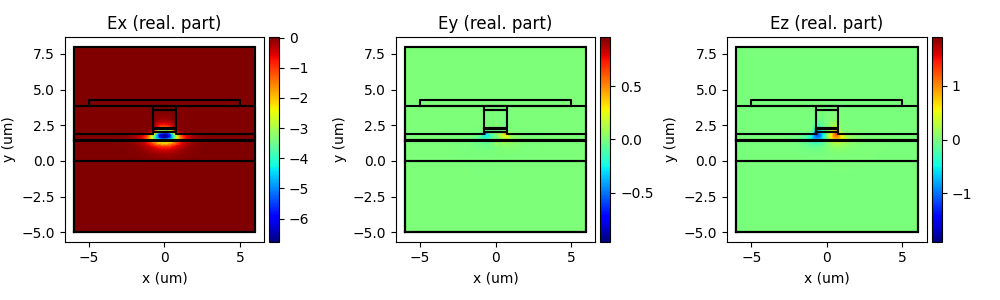

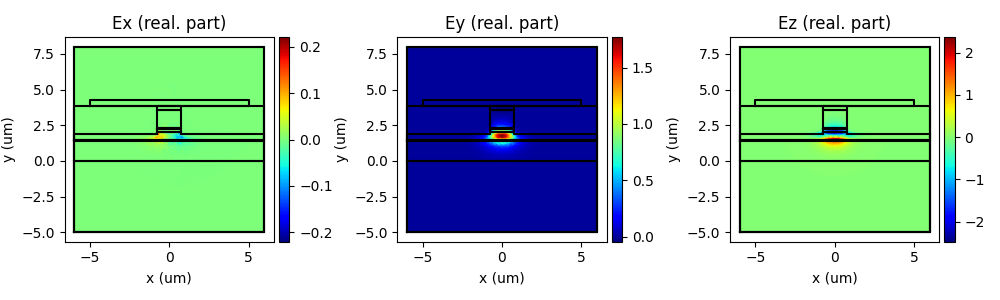

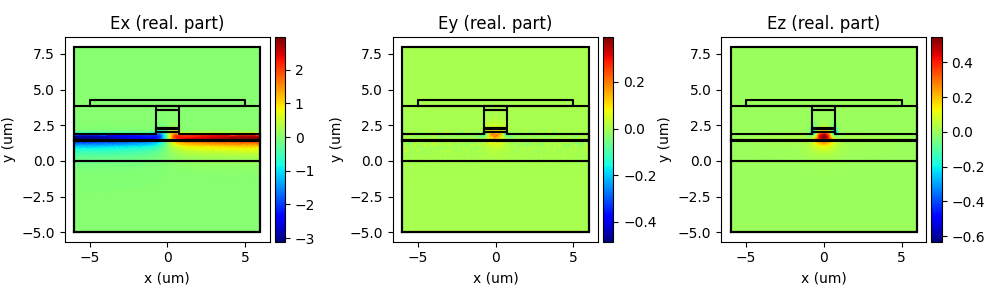

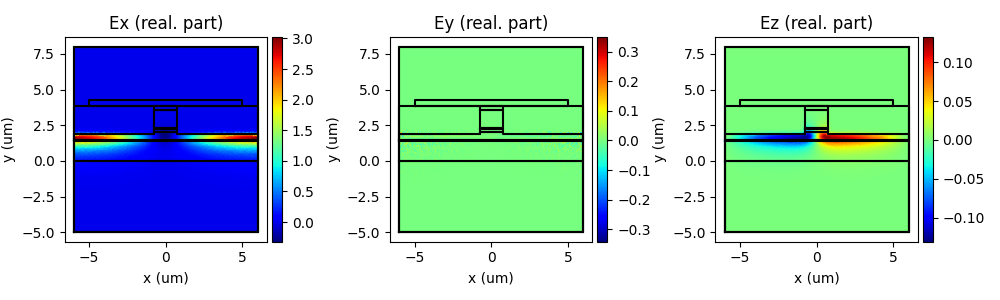

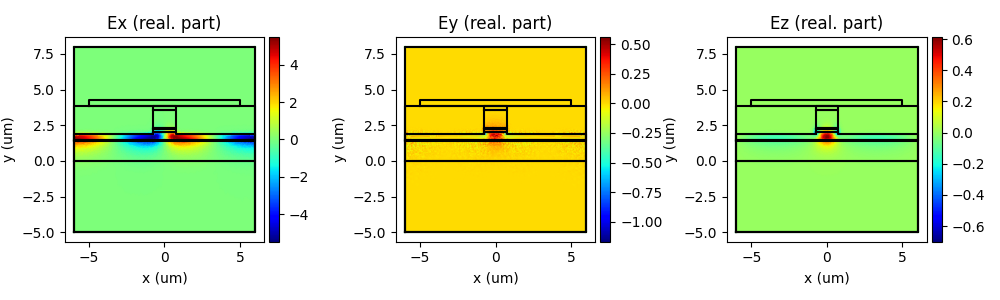

In [4]:
modes = mode.compute_modes(
    wavelength=1.56,
    num_modes=5,
    order=1,
    metallic_boundaries=["top", "bottom", "left", "right"],
    n_guess=3.4,
    return_modes=True
)

wl = [1.54, 1.55, 1.56]
neff = [3.2537, 3.2512, 3.2483]

dneff_dwl = np.gradient(neff, wl)
ng = neff[1] - wl[1] * dneff_dwl[1]

print(f"Group index: {ng:.4f}")
for i in range(len(modes)):
    print(f'Effective index - mode {i}: {modes[i].n_eff.real:.4f}')
    print(f'loss - mode {i}: {modes[i].calculate_propagation_loss(1e4):.2f} dB/cm')
    print(f"power: ", modes[i].calculate_power())
    print(f"TE fraction: ", modes[i].te_fraction)
    print(f"TM fraction: ", modes[i].tm_fraction)
    print(f"transversality: {modes[i].transversality}")
    print('#------------------------------------------#')
	
for m in modes:
	mode.plot_mode(m)

In [5]:
mode.transfer_results_to_device(TE_TM_idx = [0,1])

Charge transport will take place with:
L6
L5
L5_1
L4
L3
L2
bcbp
Material "L2" does not have k-data defined. Returning "zeros"
Material "L3" does not have k-data defined. Returning "zeros"
Material "L4" does not have k-data defined. Returning "zeros"
Material "L5_1" does not have k-data defined. Returning "zeros"
Material "L5" does not have k-data defined. Returning "zeros"
Material "L6" does not have k-data defined. Returning "zeros"
Solving IV of the junctions...


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\solcore\sesame_drift_diffusion\solve_pdd.py:193: UserWarning: All voltages are positive, but junction has been identified as n-p, so the  open-circuit voltage (Voc) of the junction will be negative.
  warnings.warn(


Solving IV of the tunnel junctions...
Solving IV of the total solar cell...


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\traitlets\traitlets.py:1385: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  warn(


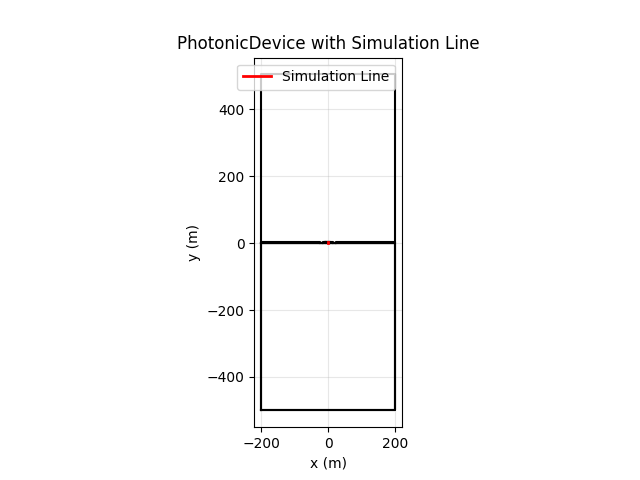

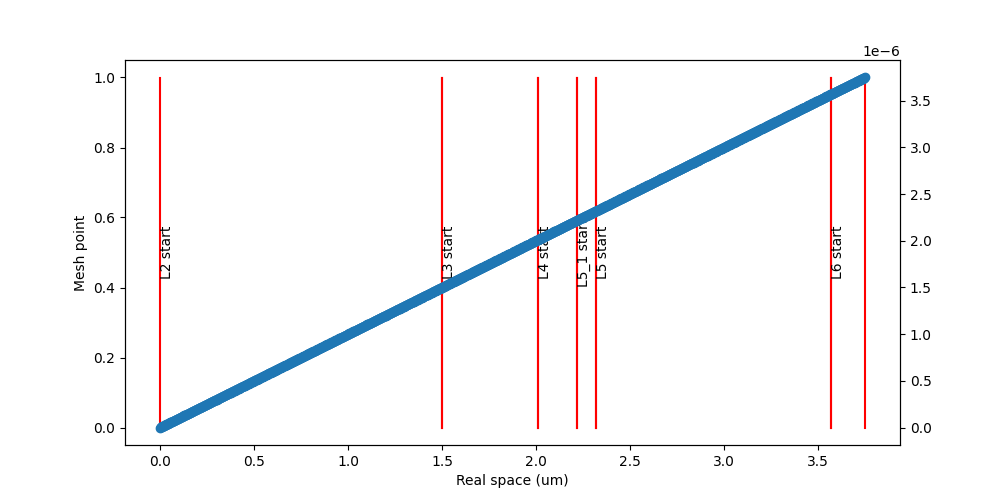

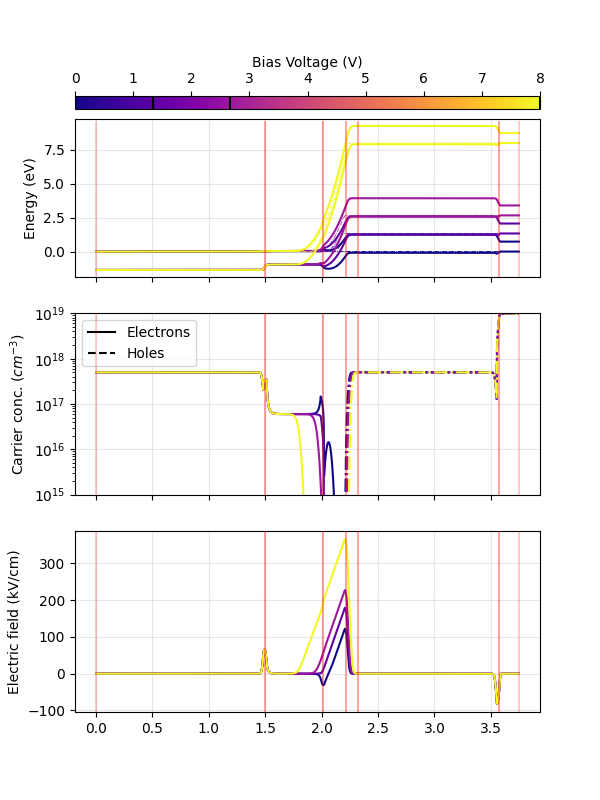

In [6]:
a=shapely.LineString([
    [0,0+0.001],
    [0,modulator.h_L1 + modulator.h_L2+modulator.h_L3+modulator.h_L4+modulator.h_L5+modulator.h_L6-0.001]]
)
 
charge=ChargeSimulatorSolcore(
    device=modulator.device,
    simulation_line=a,
    bias_start_stop_step=[0,8,31]
)

fig, ax = charge.plot_with_simulation_line()
charge.plot_mesh()

charge.solve_PDD(
    verbose = True*0,
    tol = 1e-6,
    max_iter = 1000,
    smooth_output=True,
    savgol_window = 10
)

charge.plot_results(
    V_idx = [0, 5, 10, 30],
    cmap = 'plasma'
)
charge.transfer_results_to_device(
	dx = 0.5,
	polygons_to_map = ['L1', 'L2', 'L3', 'L4', 'L5', 'L6', 'L5_1'])

15790


c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\traitlets\traitlets.py:1385: DeprecationWarning: Passing unrecognized arguments to super(Toolbar).__init__().
NavigationToolbar2WebAgg.__init__() missing 1 required positional argument: 'canvas'
This is deprecated in traitlets 4.2.This error will be raised in a future release of traitlets.
  warn(


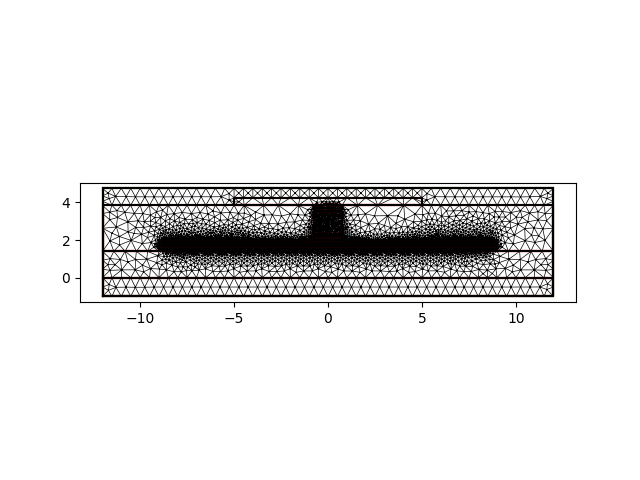

In [7]:
EO=ElectroOpticalSimulator(
    device=modulator.device,
    simulation_window=shapely.box(
        -modulator.w_metal_sig/2-modulator.metal_sep/2-2,
        -modulator.h_L1-1,
        +modulator.w_metal_sig/2+modulator.metal_sep/2+2,
        modulator.h_L2+modulator.h_L3+modulator.h_L4+modulator.h_L5+modulator.h_L6+1
    ),
	wavelength=1550
)

EO.make_mesh()
fig, ax = EO.plot_mesh()
EO.plot_polygons(ax=ax)

print(EO.mesh.nelements)

In [8]:
EO.get_epsilon_optical()

c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: invalid value encountered in sqrt
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: divide by zero encountered in log
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facets\numpy\numpy_func.py:322: RuntimeWarning: overflow encountered in exp
  result_magnitude = func(*stripped_args, **stripped_kwargs)
c:\Users\20230622\AppData\Local\anaconda3\envs\imodulator_venv\lib\site-packages\pint\facet

['Bandfilling', 'Plasma', 'Intervalence', 'Pockels', 'Kerr']


<Axes: >

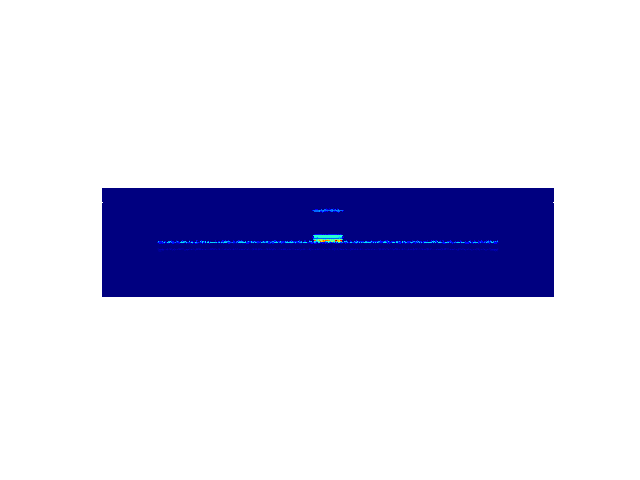

In [9]:
print(EO.epsilon_optical['InGaAsPElectroOpticalModel']['labels'])
EO.basis.plot(EO.epsilon_optical['InGaAsPElectroOpticalModel']['dperms'][0,0,:,-1,4].real)

In [10]:
kappa_all_TE = []
kappa_all_TM = []
voltage_idxs = np.arange(0, len(modulator.device.charge['V']), 1)

manager = enlighten.get_manager()
pbar = manager.counter(total=len(voltage_idxs), desc='Calculating EO response', unit='voltage index')
for i in range(len(modulator.device.charge['V'])):
    kappa = EO.calculate_EO_response(
        voltage_idx=i,
        rot_x=0,
        rot_y=np.pi/4,
        rot_z=0,
        base_epsilon_voltage_idx=0,
        optical_mode_a='TE',
        optical_mode_b='TE',
    )
    kappa_all_TE.append(kappa['InGaAsPElectroOpticalModel']['results'])

    kappa = EO.calculate_EO_response(
        voltage_idx=i,
        rot_x=0,
        rot_y=np.pi/4,
        rot_z=0,
        base_epsilon_voltage_idx=0,
        optical_mode_a='TM',
        optical_mode_b='TM',
    )
    kappa_all_TM.append(kappa['InGaAsPElectroOpticalModel']['results'])

    pbar.update()

In [11]:
kappa_all_TE = np.array(kappa_all_TE)
kappa_all_TM = np.array(kappa_all_TM)

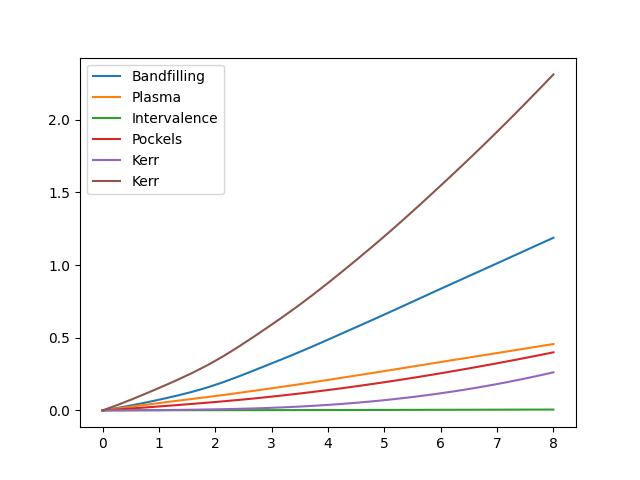

In [12]:
plt.figure()
for i in range(5):
    plt.plot(modulator.device.charge['V'], kappa_all_TE[:, i].real*1e-3, label=f"{kappa['InGaAsPElectroOpticalModel']['labels'][i]}")

plt.plot(modulator.device.charge['V'], np.sum(kappa_all_TE.real, axis=1)*1e-3, label=f"{kappa['InGaAsPElectroOpticalModel']['labels'][i]}")
plt.legend()

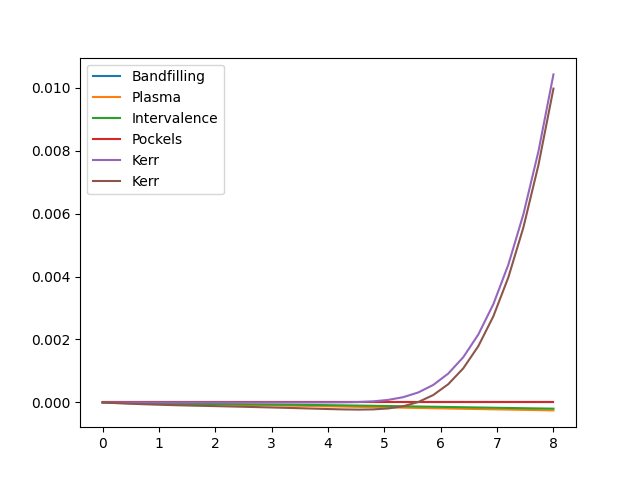

In [13]:
plt.figure()
for i in range(5):
    plt.plot(modulator.device.charge['V'], kappa_all_TE[:, i].imag*1e-3, label=f"{kappa['InGaAsPElectroOpticalModel']['labels'][i]}")

plt.plot(modulator.device.charge['V'], np.sum(kappa_all_TE.imag, axis=1)*1e-3, label=f"{kappa['InGaAsPElectroOpticalModel']['labels'][i]}")
plt.legend()

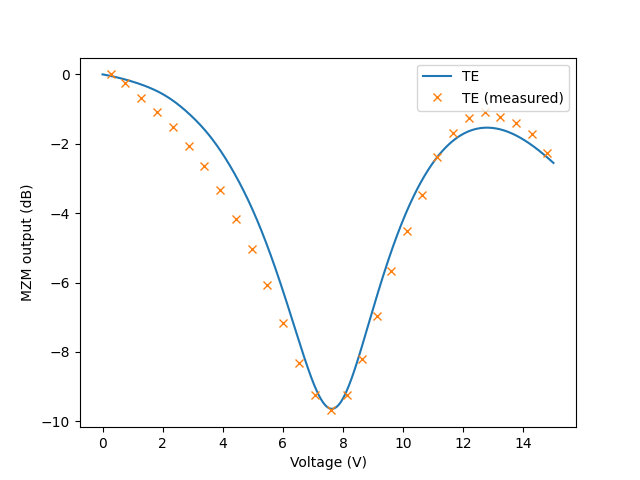

: 

In [ ]:
data_meas_TE = [
    [14.796323298360168, -13.73546536430171],
    [14.285130087341383, -13.19260573264027],
    [13.759472266188201, -12.874489599517855],
    [13.2337389984977, -12.69343467585448],
    [12.707982258551148, -12.555021017356133],
    [12.182059536222496, -12.718142019667663],
    [11.655982567639777, -13.161477050206557],
    [11.129771471879604, -13.848476453117076],
    [10.627230201505965, -14.956345702069711],
    [10.12474032419582, -15.970850885675283],
    [9.598273827935248, -17.12182786431009],
    [9.119522143614589, -18.433001748596144],
    [8.640808983599896, -19.67418981037323],
    [8.134331050761995, -20.696820430808053],
    [7.588328893847951, -21.153370403601347],
    [7.062747078095324, -20.69717779280168],
    [6.537421221706337, -19.775992338059503],
    [6.012209373418182, -18.647692166801452],
    [5.486987465591721, -17.537666823471273],
    [4.961718613253151, -16.512924010471163],
    [4.436375990966981, -15.622196602275434],
    [3.9109897773481404, -14.810660115100493],
    [3.385536500140571, -14.120955814111355],
    [2.860022865703151, -13.540900480689448],
    [2.334499171727421, -12.979119975195413],
    [1.8088950014452188, -12.56353809312435],
    [1.283284124804144, -12.160139429671865],
    [0.757702756142109, -11.703134604297631],
    [0.27980183554035776, -11.468754399236882],
]
data_meas_TE = np.array(data_meas_TE)
# data_meas_TM = np.array(data_meas_TM)

device_length = 1.25e-3

phi = 1j*0.65*0
phi2 = -0.145*np.pi+1j*0.68
phase_change_TE = np.sum(kappa_all_TE*device_length, axis=1)
phase_change_TM = np.sum(kappa_all_TM*device_length, axis=1)
MZM_output_TE = 10*np.log10(np.abs(1/2 * (np.exp(1j*phi2) + np.exp(1j*phase_change_TE + 1j*phi)))**2)
MZM_output_TM = 10*np.log10(np.abs(1/2 * (np.exp(1j*phi2) + np.exp(1j*phase_change_TM + 1j*phi)))**2)

new_V = np.linspace(0, 15, 1000)
phase_change_TE_interp = interp1d(modulator.device.charge['V'], phase_change_TE, kind='cubic', bounds_error=False, fill_value='extrapolate')(new_V)
phase_change_TM_interp = interp1d(modulator.device.charge['V'], phase_change_TM, kind='cubic', bounds_error=False, fill_value='extrapolate')(new_V)

MZM_output_TE_interp = 10*np.log10(np.abs(1/2 * (np.exp(1j*phi2) + np.exp(1j*phase_change_TE_interp + 1j*phi)))**2)
MZM_output_TM_interp = 10*np.log10(np.abs(1/2 * (np.exp(1j*phi2) + np.exp(1j*phase_change_TM_interp + 1j*phi)))**2)

MZM_output_TE_interp -= MZM_output_TE_interp[0]
MZM_output_TM_interp -= MZM_output_TM_interp[0]
plt.figure()
plt.plot(new_V, MZM_output_TE_interp, label='TE')
# plt.plot(new_V, MZM_output_TM_interp, label='TM')
# plt.plot(modulator.device.charge['V'], MZM_output_TE, 'o', label='TE (original)')
# plt.plot(modulator.device.charge['V'], MZM_output_TM, 'o', label='TM (original)')

plt.plot(data_meas_TE[:,0], data_meas_TE[:,1] - data_meas_TE[-1,1], 'x', label='TE (measured)')
# plt.plot(data_meas_TM[:,0], data_meas_TM[:,1] - data_meas_TM[0,1], 'x', label='TM (measured)')
plt.xlabel('Voltage (V)')
plt.ylabel('MZM output (dB)')
plt.legend()
# plt.ylim(-25, 2)

np.save(
	"EO_results.npy",
	{
		'V': new_V,
		'MZM_output_TE_interp': MZM_output_TE_interp,
		'MZM_output_TM_interp': MZM_output_TM_interp,
		'phase_change_TE_interp': phase_change_TE_interp,
        'phase_change_TM_interp': phase_change_TM_interp,
		'data_meas_TE': data_meas_TE,
		'extra_phi_1': phi,
		'extra_phi_2': phi2,
    }
		        )